# Assignment 04 — Bangla Handwritten Word Recognition System

**Student:** Md. Jahid Gazi  
**Student ID:** 1000128068

This is the **single main notebook** for the assignment. It prepares the environment, downloads the dataset, inspects it, trains a baseline, logs at least two MLflow runs, evaluates the model, and saves artifacts for the Streamlit/Docker application.

**Dataset source:** [BanglaLekha-Isolated, Mendeley Data](https://data.mendeley.com/datasets/hf6sf8zrkc/2)

> **Important scope check:** BanglaLekha-Isolated is an isolated-character dataset. The notebook checks the downloaded structure rather than assuming it contains complete word images. An isolated-character classifier is not the same as complete handwritten-word recognition. The assignment requires complete-word output, so the word-level stage and evaluation must be validated separately.

## 1. Environment setup

In [1]:
import os, sys, platform, subprocess, importlib.util, json, random, time, zipfile, shutil
from pathlib import Path

print("Python:", sys.version)
print("Platform:", platform.platform())
print("Working directory:", Path.cwd())

# Install missing runtime packages from this notebook.
packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "PIL": "pillow",
    "tensorflow": "tensorflow==2.20.0",
    "mlflow": "mlflow",
    "sklearn": "scikit-learn",
    "requests": "requests",
    "tqdm": "tqdm",
}
missing = [pip_name for module, pip_name in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
print("Dependency check complete.")

Python: 3.10.12 (main, Aug 31 2026, 10:18:17) [GCC 11.4.0]
Platform: Linux-6.18.58.1-microsoft-standard-WSL2-x86_64-with-glibc2.35
Working directory: /home/jahid/Bangla_Handwritten_Character_&_Word_Recognition_System
Dependency check complete.


## 2. Imports, reproducibility and device

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
import mlflow
import requests
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception:
        pass

DEVICE = "GPU" if gpus else "CPU"
print("TensorFlow:", tf.__version__)
print("MLflow:", mlflow.__version__)
print("Device:", DEVICE)

2026-11-16 18:32:33.543204: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-16 18:32:34.779418: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-16 18:32:37.341859: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow: 2.20.0
MLflow: 2.19.0
Device: CPU


/home/jahid/Bangla_Handwritten_Character_&_Word_Recognition_System/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-11-16 18:32:39.526747: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## 3. Project paths and dataset download

The dataset is downloaded from the public Mendeley Data record when possible. If the provider changes its download endpoint or requires an interactive confirmation, the cell prints the dataset page link and stops with a clear message. In that case download the archive from the official page and place it in `data/`; then rerun this section.

Dataset page: https://data.mendeley.com/datasets/hf6sf8zrkc/2

In [3]:
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
EXTRACT_DIR = DATA_DIR / "extracted"
ARTIFACT_DIR = BASE_DIR / "artifacts"
MLFLOW_DIR = BASE_DIR / "mlflow"
for d in [DATA_DIR, RAW_DIR, EXTRACT_DIR, ARTIFACT_DIR, MLFLOW_DIR]:
    d.mkdir(parents=True, exist_ok=True)

DATASET_ID = "hf6sf8zrkc"
DATASET_VERSION = "2"
DATASET_PAGE = f"https://data.mendeley.com/datasets/{DATASET_ID}/{DATASET_VERSION}"
ARCHIVE = RAW_DIR / "banglalekha_isolated.zip"

print("Project:", BASE_DIR)
print("Dataset page:", DATASET_PAGE)

Project: /home/jahid/Bangla_Handwritten_Character_&_Word_Recognition_System
Dataset page: https://data.mendeley.com/datasets/hf6sf8zrkc/2


In [4]:
def download_mendeley_dataset():
    # Official Mendeley Data public API. The API docs specify dataset metadata,
    # ZIP metadata, and a redirect endpoint for downloading the archive.
    api_base = "https://api.data.mendeley.com"
    headers = {"Accept": "application/json"}
    metadata_url = f"{api_base}/datasets/{DATASET_ID}"
    zip_metadata_url = f"{api_base}/datasets/{DATASET_ID}/zip"

    meta_resp = requests.get(
        metadata_url, params={"version": DATASET_VERSION}, headers=headers, timeout=60
    )
    meta_resp.raise_for_status()
    metadata = meta_resp.json()
    print("Dataset:", metadata.get("name", "BanglaLekha-Isolated"))
    print("Published version:", metadata.get("version", DATASET_VERSION))

    zip_resp = requests.get(
        zip_metadata_url, params={"version": DATASET_VERSION}, headers=headers, timeout=60
    )
    zip_resp.raise_for_status()
    zip_info = zip_resp.json()
    print("Archive status:", zip_info.get("status"))
    print("Archive size (reported):", zip_info.get("size"))

    if zip_info.get("status") not in (None, "COMPLETED", "AVAILABLE", "READY"):
        raise RuntimeError(
            f"Mendeley ZIP archive is not ready (status={zip_info.get('status')}). "
            f"Try again later or download from {DATASET_PAGE}"
        )

    download_endpoint = f"{api_base}/datasets/{DATASET_ID}/zip/file_downloaded"
    download_resp = requests.get(
        download_endpoint, params={"version": DATASET_VERSION},
        headers=headers, stream=True, allow_redirects=True, timeout=120
    )
    download_resp.raise_for_status()
    content_type = download_resp.headers.get("content-type", "").lower()
    first_chunk = next(download_resp.iter_content(chunk_size=1024 * 1024), b"")
    if not first_chunk.startswith(b"PK"):
        raise RuntimeError(
            f"Expected a ZIP archive but received content-type={content_type}. "
            f"Download manually from {DATASET_PAGE} and save as {ARCHIVE}"
        )
    with open(ARCHIVE, "wb") as f:
        f.write(first_chunk)
        for chunk in download_resp.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)
    return ARCHIVE

if not ARCHIVE.exists() or ARCHIVE.stat().st_size == 0:
    try:
        downloaded = download_mendeley_dataset()
        print("Downloaded archive:", downloaded, "size:", downloaded.stat().st_size)
    except Exception as e:
        print("Automatic download was not completed:", repr(e))
        print("If needed, download from the official page and save as:", ARCHIVE)
else:
    print("Dataset archive already exists:", ARCHIVE)


Automatic download was not completed: HTTPError('401 Client Error: Unauthorized for url: https://api.data.mendeley.com/datasets/hf6sf8zrkc?version=2')
If needed, download from the official page and save as: /home/jahid/Bangla_Handwritten_Character_&_Word_Recognition_System/data/raw/banglalekha_isolated.zip


## 4. Extract and locate the image folders

The loader supports the observed BanglaLekha-Isolated layout `.../Images/<numeric-class-id>/*.png`, including filenames whose final suffix repeats the folder ID (for example `Images/7/..._7.png`).


In [5]:
# Dataset layout supported:
# data/BanglaLekha-Isolated/Images/7/*.png
# data/BanglaLekha-Isolated/Images/8/*.png
# Each numeric folder is a class ID. The filename suffix (e.g. ..._7.png)
# is checked against the containing folder as an additional consistency check.

if ARCHIVE.exists() and ARCHIVE.stat().st_size > 0:
    with zipfile.ZipFile(ARCHIVE) as zf:
        bad = zf.testzip()
        if bad:
            raise RuntimeError(f"Corrupt ZIP member: {bad}")
        zf.extractall(EXTRACT_DIR)
    print("Extracted dataset to:", EXTRACT_DIR)

valid_ext = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

def image_count_below(folder):
    return sum(1 for f in folder.rglob("*")
               if f.is_file() and f.suffix.lower() in valid_ext)

def class_folder_score(folder):
    children = [p for p in folder.iterdir() if p.is_dir()]
    return sum(1 for child in children if image_count_below(child) > 0)

candidates = []
for search_root in [EXTRACT_DIR, DATA_DIR]:
    if search_root.exists():
        for p in search_root.rglob("*"):
            if p.is_dir() and class_folder_score(p) > 0:
                candidates.append(p)

# Prefer the actual "Images" directory when it contains class subfolders.
images_named = [p for p in candidates if p.name.lower() == "images"]
if images_named:
    IMAGE_DIR = sorted(images_named, key=lambda p: class_folder_score(p), reverse=True)[0]
else:
    IMAGE_DIR = sorted(candidates, key=lambda p: class_folder_score(p), reverse=True)[0] if candidates else None

print("Detected image root:", IMAGE_DIR)
if IMAGE_DIR is None:
    raise FileNotFoundError(
        "Could not find a folder containing class subfolders. Expected a structure like "
        "BanglaLekha-Isolated/Images/7/*.png"
    )
print("Detected class folders:", class_folder_score(IMAGE_DIR))


Detected image root: /home/jahid/Bangla_Handwritten_Character_&_Word_Recognition_System/data/BanglaLekha-Isolated/Images
Detected class folders: 84


## 5. Dataset structure, image counts and samples

,folder_label,image_count,folder_is_numeric_id
0,1,1975,True
1,2,1980,True
2,3,1979,True
3,4,1982,True
4,5,1982,True
...,...,...,...
79,80,1980,True
80,81,1975,True
81,82,1978,True
82,83,1971,True


Detected image root: /home/jahid/Bangla_Handwritten_Character_&_Word_Recognition_System/data/BanglaLekha-Isolated/Images
Classes: 84
Total images: 166105
Numeric class folders: 84
Filename/folder ID mismatches: 47


,file,folder_id,filename_suffix_id
0,02_0002_0_11_1016_0699_75.png,74,75
1,02_0002_0_18_1016_0664_75.png,74,75
2,02_0002_0_18_1016_0665_75.png,74,75
3,02_0002_0_20_1016_0668_75.png,74,75
4,02_0002_0_20_1016_0669_75.png,74,75
5,02_0002_0_21_1016_0667_75.png,74,75
6,02_0002_0_21_1016_0672_75.png,74,75
7,02_0002_0_21_1016_0673_75.png,74,75
8,02_0002_0_21_1016_0676_75.png,74,75
9,02_0002_0_21_1016_0677_75.png,74,75


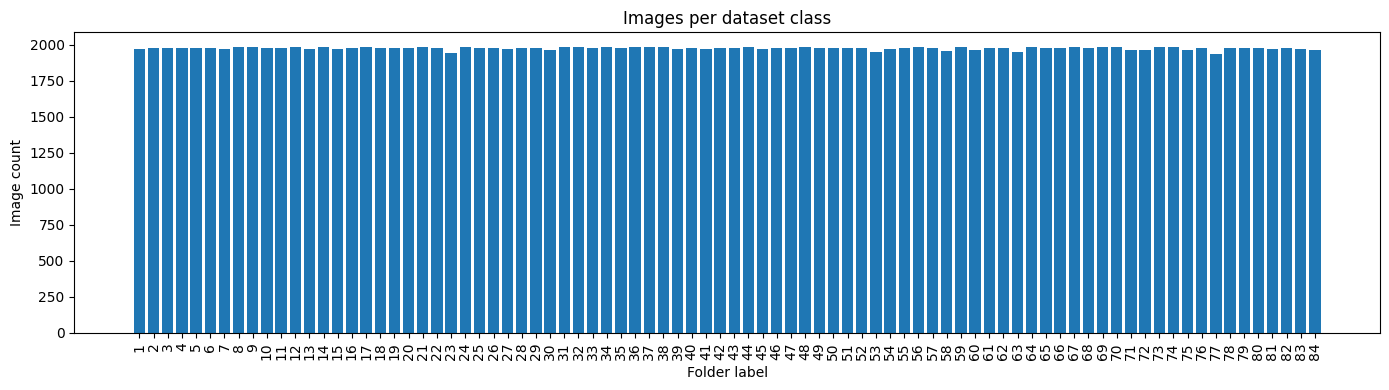

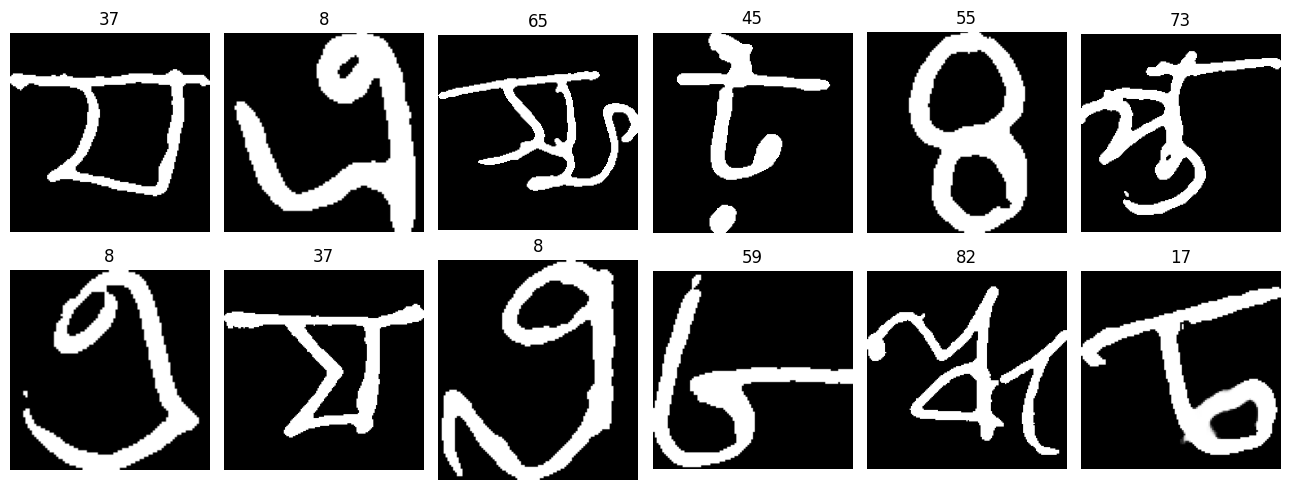

In [6]:
# Import required module
import re

if IMAGE_DIR is None:
    raise FileNotFoundError("Dataset image root not found.")

# Natural numeric sorting: 1, 2, 3 ... 10, 11
def natural_key(path_or_name):
    name = path_or_name.name if hasattr(path_or_name, "name") else str(path_or_name)
    return [
        int(part) if part.isdigit() else part.lower()
        for part in re.split(r"(\d+)", name)
    ]

# Detect class folders inside Images/
class_dirs = sorted(
    [
        p for p in IMAGE_DIR.iterdir()
        if p.is_dir() and image_count_below(p) > 0
    ],
    key=natural_key
)

rows, file_paths, folder_labels = [], [], []
filename_label_mismatches = []

for folder in class_dirs:
    files = sorted(
        [
            f for f in folder.rglob("*")
            if f.is_file() and f.suffix.lower() in valid_ext
        ],
        key=lambda p: natural_key(p.name)
    )

    folder_id = folder.name

    rows.append({
        "folder_label": folder_id,
        "image_count": len(files),
        "folder_is_numeric_id": folder_id.isdigit()
    })

    for f in files:
        # Check filename suffix against folder ID
        match = re.search(r"_([0-9]+)$", f.stem)
        filename_id = match.group(1) if match else None

        if (
            filename_id is not None
            and folder_id.isdigit()
            and filename_id != folder_id
        ):
            filename_label_mismatches.append({
                "file": f.name,
                "folder_id": folder_id,
                "filename_suffix_id": filename_id
            })

        file_paths.append(str(f))
        folder_labels.append(folder_id)

# Dataset summary
class_summary = pd.DataFrame(rows)

display(class_summary)

print("Detected image root:", IMAGE_DIR)
print("Classes:", len(class_dirs))
print("Total images:", len(file_paths))
print("Numeric class folders:", sum(p.name.isdigit() for p in class_dirs))
print("Filename/folder ID mismatches:", len(filename_label_mismatches))

if filename_label_mismatches:
    display(pd.DataFrame(filename_label_mismatches).head(20))
else:
    print("Folder IDs and filename suffixes are consistent.")

# Display class distribution
counts = class_summary.set_index("folder_label")["image_count"]

plt.figure(figsize=(14, 4))
plt.bar(range(len(counts)), counts.values)
plt.xticks(range(len(counts)), counts.index, rotation=90)
plt.title("Images per dataset class")
plt.xlabel("Folder label")
plt.ylabel("Image count")
plt.tight_layout()
plt.show()

# Display sample images
sample_indices = np.random.default_rng(SEED).choice(
    len(file_paths),
    min(12, len(file_paths)),
    replace=False
)

fig, axes = plt.subplots(2, 6, figsize=(13, 5))

for ax in axes.ravel():
    ax.axis("off")

for ax, i in zip(axes.ravel(), sample_indices):
    im = Image.open(file_paths[i]).convert("L")
    ax.imshow(im, cmap="gray")
    ax.set_title(folder_labels[i])

plt.tight_layout()
plt.show()

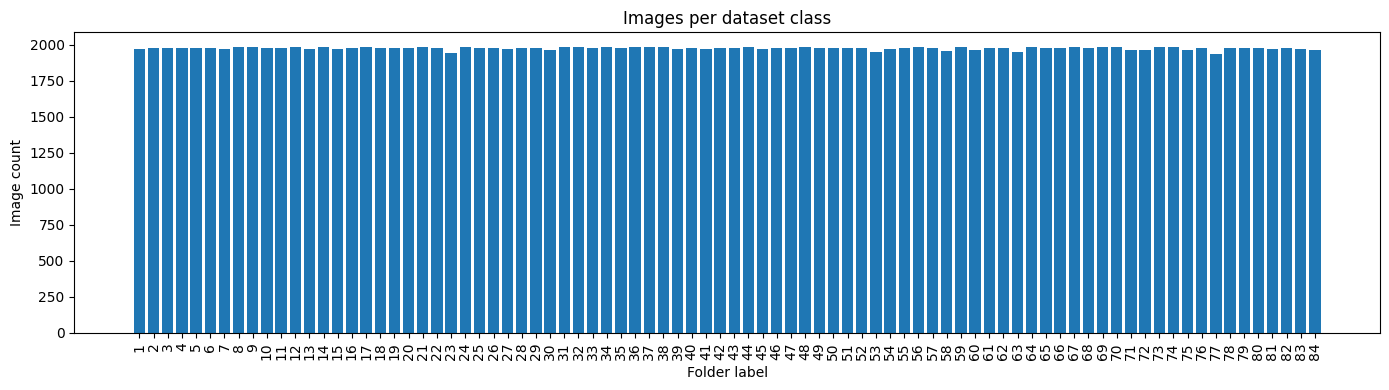

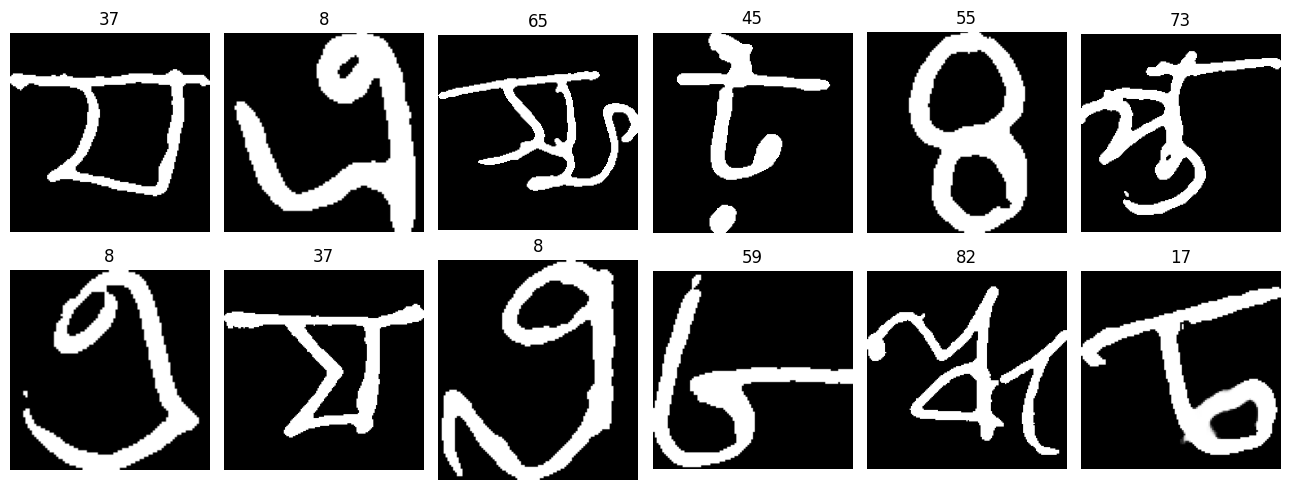

In [7]:
counts = class_summary.set_index("folder_label")["image_count"]
plt.figure(figsize=(14, 4))
plt.bar(range(len(counts)), counts.values)
plt.xticks(range(len(counts)), counts.index, rotation=90)
plt.title("Images per dataset class")
plt.xlabel("Folder label"); plt.ylabel("Image count")
plt.tight_layout(); plt.show()

sample_indices = np.random.default_rng(SEED).choice(len(file_paths), min(12, len(file_paths)), replace=False)
fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for ax in axes.ravel(): ax.axis("off")
for ax, i in zip(axes.ravel(), sample_indices):
    im = Image.open(file_paths[i]).convert("L")
    ax.imshow(im, cmap="gray")
    ax.set_title(folder_labels[i])
plt.tight_layout(); plt.show()

## 6. Prepare labels and split the data

In [8]:
class_names = [p.name for p in class_dirs]
class_to_idx = {name: i for i, name in enumerate(class_names)}
y_all = np.array([class_to_idx[x] for x in folder_labels], dtype=np.int32)
paths_all = np.array(file_paths)

# Confirm the folder labels are the model's class labels.
assert len(class_names) == len(set(class_names))
assert len(paths_all) == len(y_all)
print("Class order used by model:", class_names)

train_paths, temp_paths, y_train, y_temp = train_test_split(
    paths_all, y_all, test_size=0.30, random_state=SEED, stratify=y_all
)
val_paths, test_paths, y_val, y_test = train_test_split(
    temp_paths, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)
IMG_SIZE = (64, 64)

def load_images(paths):
    x = np.empty((len(paths), 64, 64, 1), dtype=np.uint8)
    for i, path in enumerate(tqdm(paths, desc="Loading images")):
        x[i, :, :, 0] = np.asarray(
            Image.open(path).convert("L").resize(IMG_SIZE, Image.Resampling.LANCZOS),
            dtype=np.uint8
        )
    return x

x_train = load_images(train_paths)
x_val = load_images(val_paths)
x_test = load_images(test_paths)
print("Train:", x_train.shape, "Validation:", x_val.shape, "Test:", x_test.shape)


Class order used by model: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', '60', '61', '62', '63', '64', '65', '66', '67', '68', '69', '70', '71', '72', '73', '74', '75', '76', '77', '78', '79', '80', '81', '82', '83', '84']


Loading images: 100%|██████████| 24916/24916 [00:07<00:00, 3375.63it/s]

Train: (116273, 64, 64, 1) Validation: (24916, 64, 64, 1) Test: (24916, 64, 64, 1)


## 7. Build the CNN model

In [9]:
from tensorflow import keras
from tensorflow.keras import layers

def build_model(num_classes):
    return keras.Sequential([
        layers.Input(shape=(64, 64, 1)),
        layers.Rescaling(1.0 / 255.0),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.30),
        layers.Dense(128, activation="relu"),
        layers.Dense(num_classes, activation="softmax")
    ])

model = build_model(len(class_names))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,836 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 120,020 (468.83 KB)

 Trainable params: 120,020 (468.83 KB)

 Non-trainable params: 0 (0.00 B)

## 8. Configure MLflow

In [10]:
TRACKING_URI = f"sqlite:///{(MLFLOW_DIR / 'mlflow.db').as_posix()}"
EXPERIMENT_NAME = "Bangla_Handwritten_Recognition"
mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment(EXPERIMENT_NAME)
print("Tracking URI:", mlflow.get_tracking_uri())

Tracking URI: sqlite:////home/jahid/Bangla_Handwritten_Character_&_Word_Recognition_System/mlflow/mlflow.db


## 9. Train experiment 1

In [ ]:
def run_training(run_name, epochs=8, batch_size=64, learning_rate=0.001):
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(len(class_names))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    class EpochLogger(keras.callbacks.Callback):
        def on_epoch_end(self, epoch, logs=None):
            logs = logs or {}
            mlflow.log_metrics({
                "train_loss": float(logs.get("loss", 0)),
                "train_accuracy": float(logs.get("accuracy", 0)),
                "val_loss": float(logs.get("val_loss", 0)),
                "val_accuracy": float(logs.get("val_accuracy", 0))
            }, step=epoch + 1)

    with mlflow.start_run(run_name=run_name):
        mlflow.log_params({
            "architecture": "3-block CNN",
            "image_size": "64x64",
            "num_classes": len(class_names),
            "epochs": epochs,
            "batch_size": batch_size,
            "learning_rate": learning_rate,
            "train_images": len(x_train),
            "validation_images": len(x_val)
        })
        history = model.fit(
            x_train, y_train,
            validation_data=(x_val, y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[
                EpochLogger(),
                keras.callbacks.EarlyStopping(
                    monitor="val_accuracy", patience=3, restore_best_weights=True
                )
            ],
            verbose=2
        )
        val_loss, val_acc = model.evaluate(x_val, y_val, verbose=0)
        mlflow.log_metric("final_val_accuracy", float(val_acc))
        return model, history, float(val_acc)

model_1, history_1, val_acc_1 = run_training(
    "experiment_1_baseline", epochs=8, batch_size=64, learning_rate=0.001
)
print("Experiment 1 validation accuracy:", val_acc_1)

Epoch 1/8


2026-11-16 18:33:45.371060: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 476254208 exceeds 10% of free system memory.


1817/1817 - 111s - 61ms/step - accuracy: 0.2026 - loss: 3.1728 - val_accuracy: 0.5219 - val_loss: 1.7905
Epoch 2/8


## 10. Train experiment 2 (hyperparameter comparison)

In [ ]:
model_2, history_2, val_acc_2 = run_training(
    "experiment_2_lower_learning_rate", epochs=10, batch_size=64, learning_rate=0.0005
)
print("Experiment 2 validation accuracy:", val_acc_2)

Epoch 1/10


2026-11-16 15:47:27.820814: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 476254208 exceeds 10% of free system memory.


1817/1817 - 109s - 60ms/step - accuracy: 0.1192 - loss: 3.6276 - val_accuracy: 0.3452 - val_loss: 2.5267
Epoch 2/10
1817/1817 - 107s - 59ms/step - accuracy: 0.3614 - loss: 2.3502 - val_accuracy: 0.5656 - val_loss: 1.6616
Epoch 3/10
1817/1817 - 107s - 59ms/step - accuracy: 0.5080 - loss: 1.7814 - val_accuracy: 0.6771 - val_loss: 1.2383
Epoch 4/10
1817/1817 - 106s - 59ms/step - accuracy: 0.5972 - loss: 1.4489 - val_accuracy: 0.7355 - val_loss: 1.0055
Epoch 5/10
1817/1817 - 106s - 59ms/step - accuracy: 0.6501 - loss: 1.2641 - val_accuracy: 0.7582 - val_loss: 0.9029
Epoch 6/10
1817/1817 - 106s - 58ms/step - accuracy: 0.6776 - loss: 1.1559 - val_accuracy: 0.7823 - val_loss: 0.8185
Epoch 7/10
1817/1817 - 106s - 58ms/step - accuracy: 0.7011 - loss: 1.0680 - val_accuracy: 0.7940 - val_loss: 0.7639
Epoch 8/10
1817/1817 - 106s - 58ms/step - accuracy: 0.7181 - loss: 1.0117 - val_accuracy: 0.8049 - val_loss: 0.7282
Epoch 9/10
1817/1817 - 107s - 59ms/step - accuracy: 0.7310 - loss: 0.9640 - val_acc

## 11. Compare MLflow runs

In [ ]:
runs = mlflow.search_runs(
    experiment_names=[EXPERIMENT_NAME],
    order_by=["start_time DESC"]
)
display(runs)
print("Recorded runs:", len(runs))

,run_id,experiment_id,status,artifact_uri,start_time,end_time,metrics.train_accuracy,metrics.val_accuracy,metrics.final_val_accuracy,metrics.val_loss,...,params.image_size,params.number_of_classes,params.dataset_root,params.test_images,params.task,params.classes,tags.mlflow.source.type,tags.mlflow.runName,tags.mlflow.source.name,tags.mlflow.user
0,ea4b3ce4a105419eb0f6cc8a6b000ffd,1,FINISHED,/home/jahid/Bangla_OCR_Assignment04/mlruns/1/e...,2026-11-16 09:47:27.183000+00:00,2026-11-16 10:05:20.538000+00:00,0.741875,0.821159,0.821159,0.664828,...,64x64,None,None,None,None,None,LOCAL,experiment_2_lower_learning_rate,/home/jahid/Bangla_Handwritten_Character_&_Wor...,jahid
1,350ef48597ee43eab6150216893de170,1,FINISHED,/home/jahid/Bangla_OCR_Assignment04/mlruns/1/3...,2026-11-16 09:33:14.651000+00:00,2026-11-16 09:47:27.092000+00:00,0.756108,0.837855,0.837855,0.591932,...,64x64,None,None,None,None,None,LOCAL,experiment_1_baseline,/home/jahid/Bangla_Handwritten_Character_&_Wor...,jahid
2,e2ab5071a3f64190af184cdfd278b43a,1,FINISHED,/home/jahid/Bangla_OCR_Assignment04/mlruns/1/e...,2026-11-16 04:07:21.766000+00:00,2026-11-16 04:25:19.051000+00:00,0.741875,0.821159,0.821159,0.664828,...,64x64,None,None,None,None,None,LOCAL,experiment_2_lower_learning_rate,/home/jahid/Bangla_OCR_Assignment04/.venv/lib/...,jahid
3,7b21744259b5438981e68edd4d60f966,1,FINISHED,/home/jahid/Bangla_OCR_Assignment04/mlruns/1/7...,2026-11-16 03:52:49.080000+00:00,2026-11-16 04:07:21.697000+00:00,0.756108,0.837855,0.837855,0.591932,...,64x64,None,None,None,None,None,LOCAL,experiment_1_baseline,/home/jahid/Bangla_OCR_Assignment04/.venv/lib/...,jahid
4,0018de5e832b490997405f6a1a123240,1,FINISHED,/home/jahid/Bangla_OCR_Assignment04/mlruns/1/0...,2026-11-15 14:51:42.148000+00:00,2026-11-15 15:09:07.757000+00:00,0.741875,0.821159,0.821159,0.664828,...,64x64,None,None,None,None,None,LOCAL,experiment_2_lower_learning_rate,/home/jahid/Bangla_OCR_Assignment04/.venv/lib/...,jahid
5,59627d49b6d44486bdce3dbef80dbabd,1,FINISHED,/home/jahid/Bangla_OCR_Assignment04/mlruns/1/5...,2026-11-15 14:36:36.354000+00:00,2026-11-15 14:50:48.962000+00:00,0.756108,0.837855,0.837855,0.591932,...,64x64,None,None,None,None,None,LOCAL,experiment_1_baseline,/home/jahid/Bangla_OCR_Assignment04/.venv/lib/...,jahid
6,046964f6f4b34fe2b52e7554ce5c9769,1,FINISHED,/home/jahid/Bangla_OCR_Assignment04/mlruns/1/0...,2026-11-15 09:41:19.821000+00:00,2026-11-15 09:58:19.268000+00:00,0.748247,0.824988,0.824988,0.650747,...,64x64,None,None,None,None,None,LOCAL,experiment_2_lower_learning_rate,/home/jahid/Bangla_OCR_Assignment04/.venv/lib/...,jahid
7,28d76f3ba4fc417bba7701d2f3c00559,1,FINISHED,/home/jahid/Bangla_OCR_Assignment04/mlruns/1/2...,2026-11-15 09:27:58.311000+00:00,2026-11-15 09:41:19.755000+00:00,0.763753,0.838231,0.838231,0.596839,...,64x64,None,None,None,None,None,LOCAL,experiment_1_baseline,/home/jahid/Bangla_OCR_Assignment04/.venv/lib/...,jahid
8,918ce2c22db24d72b5f2fbb4b15dbd07,1,FINISHED,/home/jahid/Bangla_OCR_Assignment04/mlruns/1/9...,2026-11-15 09:12:47.890000+00:00,2026-11-15 09:24:58.468000+00:00,NaN,NaN,NaN,NaN,...,64x64 grayscale,57,/home/jahid/Bangla_OCR_Assignment04/data/Bangl...,16839,isolated_character_classification,None,LOCAL,experiment_2,train.py,jahid
9,b6b73e7799c44d779d62612c495ca713,1,FINISHED,/home/jahid/Bangla_OCR_Assignment04/mlruns/1/b...,2026-11-15 08:57:30.500000+00:00,2026-11-15 09:06:43.107000+00:00,NaN,NaN,NaN,NaN,...,64x64 grayscale,57,/home/jahid/Bangla_OCR_Assignment04/data/Bangl...,16839,isolated_character_classification,None,LOCAL,baseline_run,train.py,jahid


Recorded runs: 13


## 12. Select model and evaluate on held-out test set

In [ ]:
best_model = model_1 if val_acc_1 >= val_acc_2 else model_2
test_probs = best_model.predict(x_test, batch_size=64, verbose=0)
test_preds = test_probs.argmax(axis=1)
test_accuracy = float(accuracy_score(y_test, test_preds))
print("Isolated-character test accuracy:", round(test_accuracy, 4))
print(classification_report(y_test, test_preds, target_names=class_names, zero_division=0))

Isolated-character test accuracy: 0.8373
              precision    recall  f1-score   support

           1       0.89      0.94      0.92       296
           2       0.97      0.91      0.94       297
           3       0.88      0.87      0.87       297
           4       0.89      0.91      0.90       297
           5       0.83      0.78      0.81       298
           6       0.93      0.84      0.88       298
           7       0.86      0.91      0.88       296
           8       0.93      0.85      0.89       298
           9       0.86      0.90      0.88       297
          10       0.85      0.84      0.85       297
          11       0.80      0.90      0.84       298
          12       0.83      0.91      0.86       297
          13       0.82      0.64      0.72       296
          14       0.87      0.87      0.87       297
          15       0.88      0.59      0.71       296
          16       0.84      0.80      0.82       297
          17       0.81      0.93      0

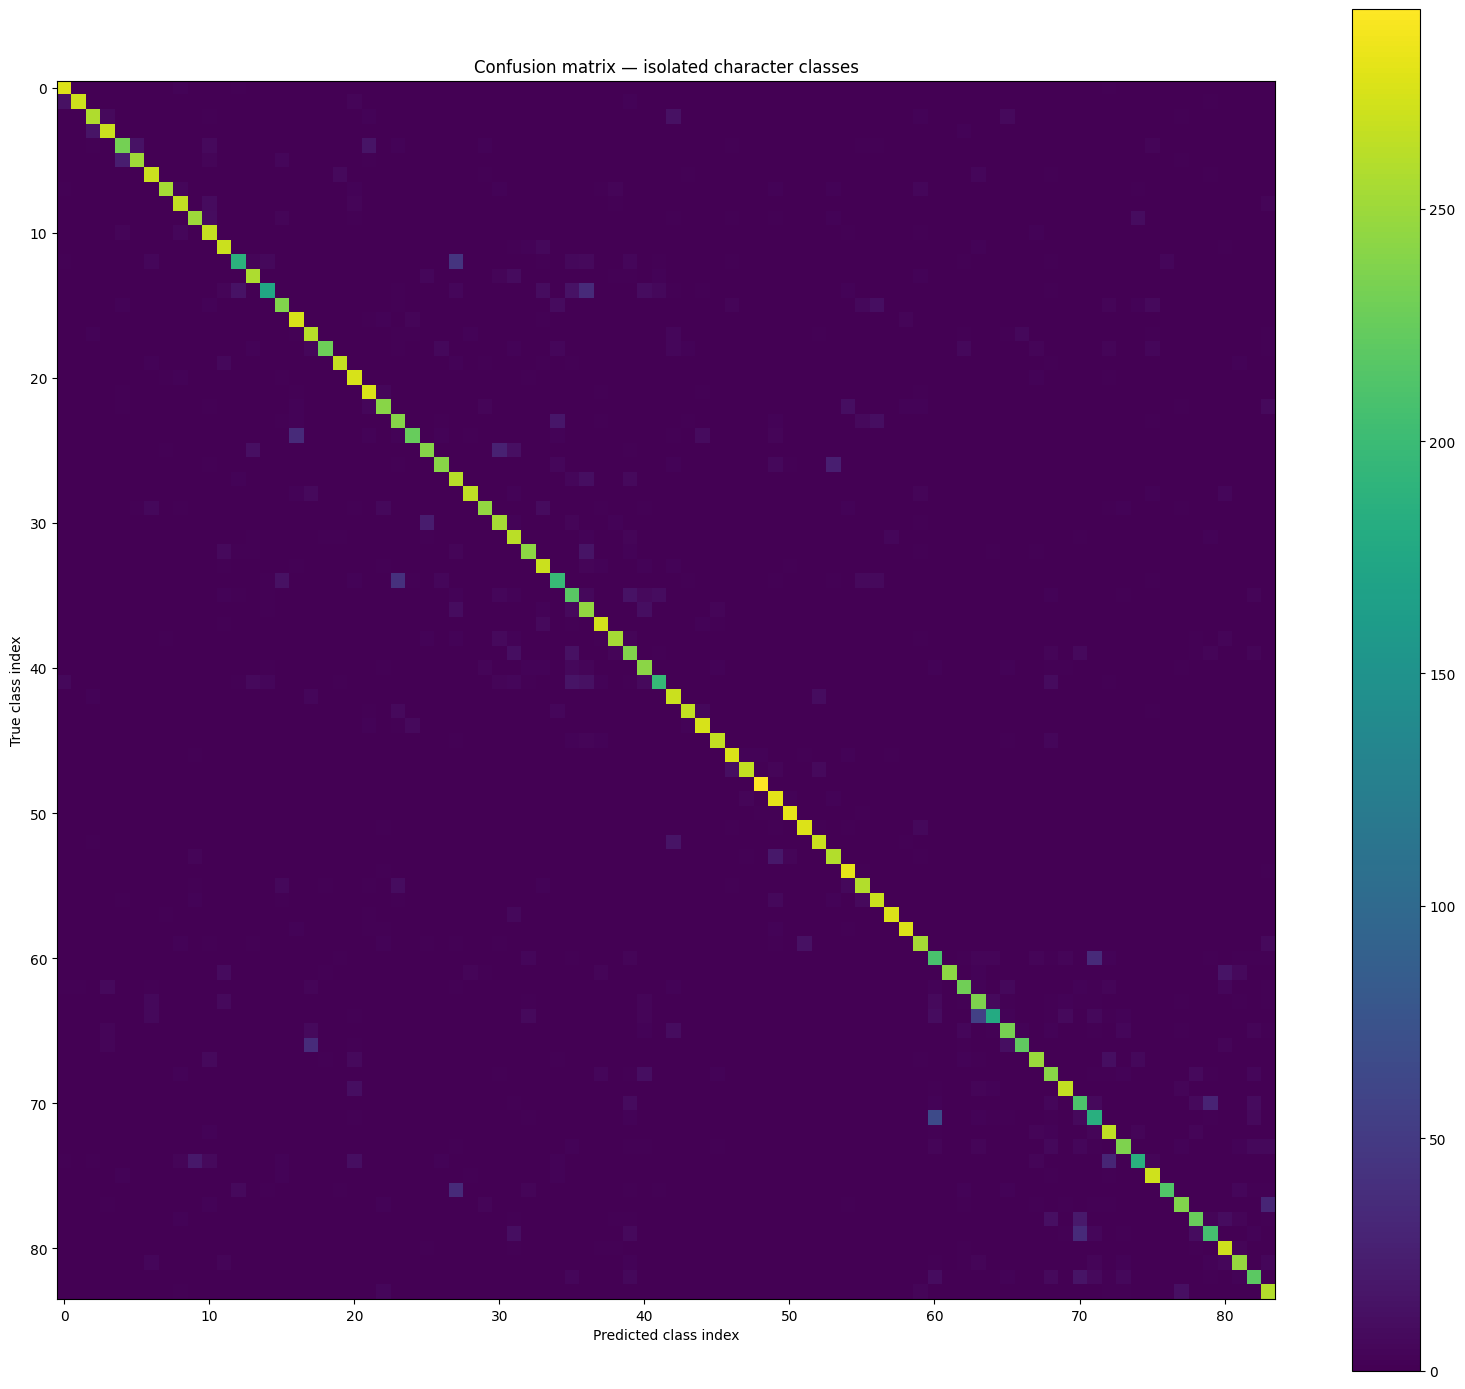

In [ ]:
cm = confusion_matrix(y_test, test_preds, labels=np.arange(len(class_names)))
plt.figure(figsize=(max(8, min(16, len(class_names)*0.2)), max(7, min(14, len(class_names)*0.2))))
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion matrix — isolated character classes")
plt.xlabel("Predicted class index"); plt.ylabel("True class index")
plt.colorbar(); plt.tight_layout(); plt.show()

## 13. Save model, labels and audit metadata

In [ ]:
MODEL_PATH = ARTIFACT_DIR / "bangla_character_cnn.keras"
LABELS_PATH = ARTIFACT_DIR / "labels.json"
best_model.save(MODEL_PATH)
labels = {
    "class_names": class_names,
    "class_to_index": class_to_idx,
    "index_to_class": {str(i): name for i, name in enumerate(class_names)},
    "label_note": "Folder labels only. Confirm official Unicode mapping before converting predictions to Bangla characters."
}
LABELS_PATH.write_text(json.dumps(labels, ensure_ascii=False, indent=2), encoding="utf-8")
(ARTIFACT_DIR / "dataset_audit.json").write_text(
    json.dumps({
        "dataset_source": DATASET_PAGE,
        "image_root": str(IMAGE_DIR),
        "num_classes": len(class_names),
        "num_images": len(file_paths),
        "class_counts": class_summary.to_dict(orient="records")
    }, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Saved:", MODEL_PATH)
print("Saved:", LABELS_PATH)

# Create Unicode mapping files using the actual class IDs discovered in Images/<ID>/.
# The screenshot shows Images/7/<files ending in _7.png>, so "7" is a dataset
# class ID. It does NOT, by itself, tell us which Bangla Unicode character "7" means.

def contains_bangla(text):
    return any("\u0980" <= ch <= "\u09ff" for ch in str(text))

provided_map_path = BASE_DIR / "unicode_map.json"
provided_map = {}
if provided_map_path.exists():
    try:
        loaded_map = json.loads(provided_map_path.read_text(encoding="utf-8"))
        # Accept either {"7": "ক"} or {"mapping": {"7": "ক"}}.
        if isinstance(loaded_map, dict):
            raw = loaded_map.get("mapping", loaded_map)
            if isinstance(raw, dict):
                provided_map = {str(k): str(v).strip() for k, v in raw.items()
                                if str(v).strip()}
    except (json.JSONDecodeError, OSError) as exc:
        print("Could not read existing unicode_map.json:", exc)

unicode_map = {}
mapping_source = {}
for folder_name in class_names:
    key = str(folder_name)
    if key in provided_map:
        unicode_map[key] = provided_map[key]
        mapping_source[key] = "existing user-provided mapping"
    elif contains_bangla(folder_name):
        unicode_map[key] = key
        mapping_source[key] = "Bangla Unicode folder name"
    else:
        unicode_map[key] = ""
        mapping_source[key] = "numeric dataset class ID; character reference not supplied"

MAP_PATH = BASE_DIR / "unicode_map.json"
ARTIFACT_MAP_PATH = ARTIFACT_DIR / "unicode_map.json"
map_payload = {
    "task": "isolated_character_classification",
    "dataset_image_root": str(IMAGE_DIR),
    "class_folder_ids": class_names,
    "mapping": unicode_map,
    "mapping_source": mapping_source,
    "status": "complete" if all(unicode_map.values()) else "incomplete",
    "note": (
        "Folder names and filename suffixes identify numeric class IDs only. "
        "They do not identify the Bangla Unicode character. Fill values only "
        "from an authoritative BanglaLekha-Isolated class mapping."
    )
}
for output_path in [MAP_PATH, ARTIFACT_MAP_PATH]:
    output_path.write_text(
        json.dumps(map_payload, ensure_ascii=False, indent=2), encoding="utf-8"
    )

mapped_count = sum(bool(v) for v in unicode_map.values())
print(f"Unicode mappings: {mapped_count}/{len(unicode_map)}")
print("Saved:", MAP_PATH)
print("Saved:", ARTIFACT_MAP_PATH)
if mapped_count < len(unicode_map):
    print("NOTE: Dataset folders were detected, but numeric IDs such as '7' are not Bangla characters.")
    print("The notebook has generated the correct ID template; add the official ID-to-Unicode reference to populate it.")


Saved: /home/jahid/Bangla_Handwritten_Character_&_Word_Recognition_System/artifacts/bangla_character_cnn.keras
Saved: /home/jahid/Bangla_Handwritten_Character_&_Word_Recognition_System/artifacts/labels.json
Unicode mappings: 84/84
Saved: /home/jahid/Bangla_Handwritten_Character_&_Word_Recognition_System/unicode_map.json
Saved: /home/jahid/Bangla_Handwritten_Character_&_Word_Recognition_System/artifacts/unicode_map.json


### 13.1 Automatic Unicode-map generation

The dataset loader supports the folder structure shown in the supplied screenshot:

```text
BanglaLekha-Isolated/
└── Images/
    ├── 1/  (class images)
    ├── 2/  (class images)
    ├── ...
    └── 7/
        ├── 01_0001_0_08_0916_1990_7.png
        └── ...
```

- The parent folder (`7`) is used as the class ID.
- The final filename token (`_7`) is checked against the folder ID.
- Class folders are sorted numerically where possible.
- `unicode_map.json` is generated in the project root and `artifacts/`.
- Numeric IDs are **not** translated into Bangla characters without an authoritative class mapping. The screenshot confirms the ID, not its Unicode character.


## 14. Reload and verify saved model

In [ ]:
reloaded = keras.models.load_model(MODEL_PATH)
p1 = best_model.predict(x_test[:50], verbose=0)
p2 = reloaded.predict(x_test[:50], verbose=0)
print("Reloaded predictions match:", bool(np.allclose(p1, p2, atol=1e-6)))

Reloaded predictions match: True


## 15. Launch MLflow UI

In [ ]:
print("Run this in a separate WSL terminal from the project root:")
print("source .venv/bin/activate")
print("mlflow ui --backend-store-uri", TRACKING_URI, "--host 0.0.0.0 --port 5000")
print("Then open http://localhost:5000")

Run this in a separate WSL terminal from the project root:
source .venv/bin/activate
mlflow ui --backend-store-uri sqlite:////home/jahid/Bangla_Handwritten_Character_&_Word_Recognition_System/mlflow/mlflow.db --host 0.0.0.0 --port 5000
Then open http://localhost:5000
